In [1]:
import sys
sys.path.append("..")  # pour importer le dossier src depuis notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from src.db import mongo_db, pg_engine

prices = pd.read_sql("SELECT * FROM price_features ORDER BY ticker, date",
                     pg_engine(), parse_dates=["date"])
print(prices.shape)
prices.isna().sum()

(7614, 11)


date                  0
ticker                0
company               0
close                 0
adj_close             0
volume                0
daily_return_pct     10
ma_7                  0
ma_30                 0
volatility_30_pct    20
target_up            10
dtype: int64

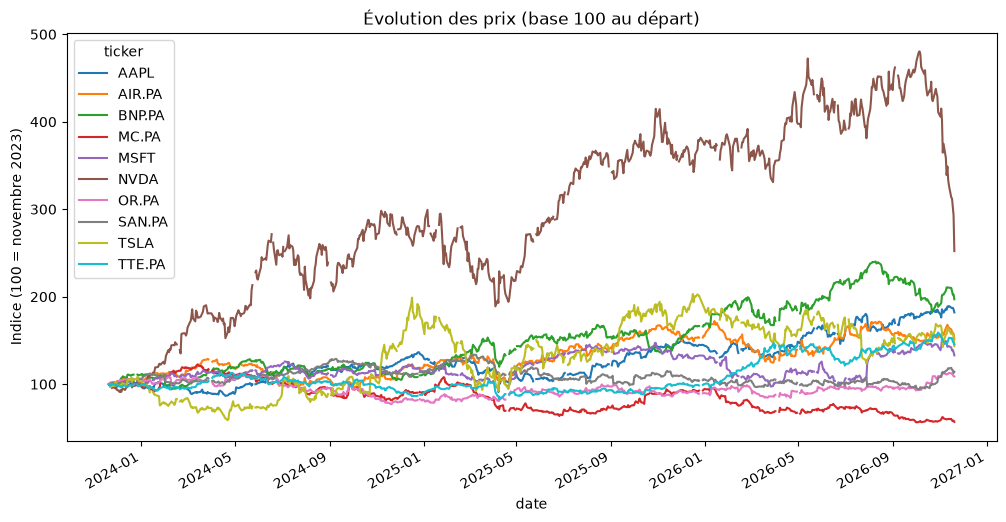

In [2]:
pivot = prices.pivot(index="date", columns="ticker", values="adj_close")
base100 = pivot / pivot.bfill().iloc[0] * 100

ax = base100.plot(figsize=(12, 6), title="Évolution des prix (base 100 au départ)")
ax.set_ylabel("Indice (100 = novembre 2023)")
plt.savefig("../docs/figures/evolution_base100.png", dpi=150, bbox_inches="tight")
plt.show()


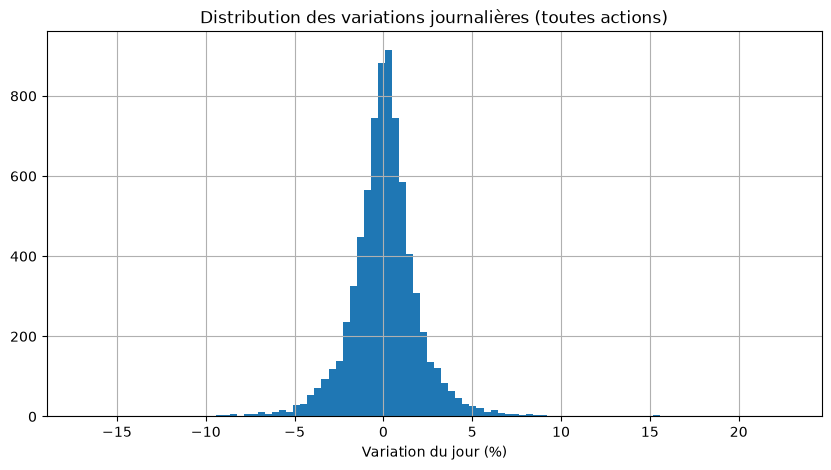

count    7604.000000
mean        0.064779
std         2.079730
min       -16.968200
25%        -0.902200
50%         0.069650
75%         1.001700
max        22.690000
Name: daily_return_pct, dtype: float64

In [3]:
ax = prices["daily_return_pct"].hist(bins=100, figsize=(10, 5))
ax.set_title("Distribution des variations journalières (toutes actions)")
ax.set_xlabel("Variation du jour (%)")
plt.savefig("../docs/figures/distribution_variations.png", dpi=150, bbox_inches="tight")
plt.show()

prices["daily_return_pct"].describe()

In [4]:
prices["next_return_pct"] = prices.groupby("ticker")["daily_return_pct"].shift(-1)
correlation = (prices.groupby("ticker")
               .apply(lambda g: g["daily_return_pct"].corr(g["next_return_pct"]))
               .round(3).sort_values())
correlation


ticker
NVDA     -0.079
OR.PA    -0.055
SAN.PA   -0.040
AIR.PA   -0.024
TSLA     -0.017
MC.PA     0.021
AAPL      0.027
BNP.PA    0.027
MSFT      0.027
TTE.PA    0.055
dtype: float64

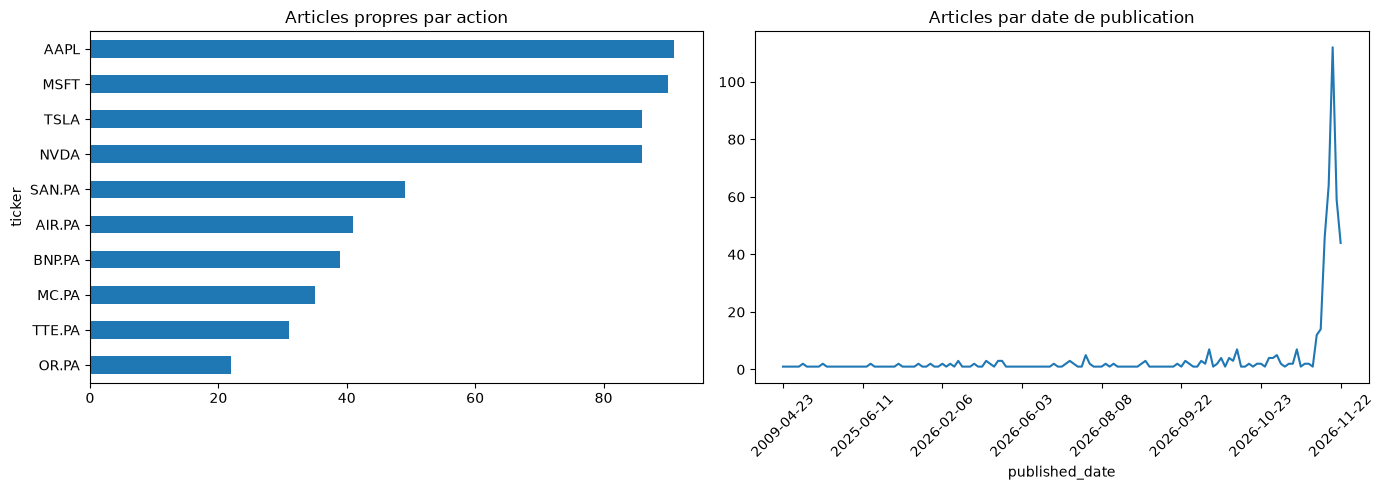

Période couverte : 2009-04-23 → 2026-11-22


source
Yahoo Finance         91
Idéal Investisseur    42
MarketBeat            32
ad-hoc-news.de        31
Morningstar           29
The Motley Fool       29
CNBC                  23
Benzinga              22
24/7 Wall St.         16
Barron's              15
Name: count, dtype: int64

In [5]:
articles = pd.DataFrame(mongo_db()["articles_clean"].find(
    {}, {"_id": 0, "ticker": 1, "published_date": 1, "source": 1}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
articles["ticker"].value_counts().sort_values().plot.barh(
    ax=axes[0], title="Articles propres par action")
articles["published_date"].value_counts().sort_index().plot(
    ax=axes[1], title="Articles par date de publication", rot=45)
plt.tight_layout()
plt.savefig("../docs/figures/articles.png", dpi=150, bbox_inches="tight")
plt.show()

print("Période couverte :", articles["published_date"].min(), "→", articles["published_date"].max())
articles["source"].value_counts().head(10)